# COU 07506 Digital Signal Processing Week 03: Convolution, Correlation and Difference Equations

* **Name:** Ismail Mbarouk Said
* **Class:** BEng24COE
* **Group:** 1
* **Registration No.:** 240242438521
* **Date:** 2026-11-25
* **Instructor checkpoints signed:** [ ] 1  [ ] 2

Task 3.1 — Convolution from the definition

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

# Task 3.1: Convolution from the definition
def conv(x, h):
    x = np.asarray(x, dtype=float)
    h = np.asarray(h, dtype=float)
    N = len(x) + len(h) - 1
    y = np.zeros(N, dtype=float)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

# Mfano wa mwongozo
print("Manual example (conv):       ", conv([1, 2, 3, 1], [1, 1, 1]))
print("Manual example (np.convolve):", np.convolve([1, 2, 3, 1], [1, 1, 1]))

# Uhakiki wa Pre-lab (a): x(n) = {1, -1, 2} na h(n) = {2, 1, 0, 1}
x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]
y_pre_loop = conv(x_pre, h_pre)
y_pre_np = np.convolve(x_pre, h_pre)
print("\nPre-lab (a) conv:       ", y_pre_loop)
print("Pre-lab (a) np.convolve:", y_pre_np)
print("Matches:", np.allclose(y_pre_loop, y_pre_np))

# Kipimo cha muda kwa mawimbi mawili ya urefu 2000
rng = np.random.default_rng(42)
a_sig = rng.standard_normal(2000)
b_sig = rng.standard_normal(2000)

t0 = time.perf_counter()
y_loop_2000 = conv(a_sig, b_sig)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
y_np_2000 = np.convolve(a_sig, b_sig)
t_np = time.perf_counter() - t0

print(f"\nLength 2000 -> conv loop time: {t_loop:.6f} s | np.convolve time: {t_np:.6f} s")
print(f"Speed-up factor: {t_loop / t_np:.1f}x | Outputs match: {np.allclose(y_loop_2000, y_np_2000)}")

Manual example (conv):        [1. 3. 6. 6. 4. 1.]
Manual example (np.convolve): [1 3 6 6 4 1]

Pre-lab (a) conv:        [ 2. -1.  3.  3. -1.  2.]
Pre-lab (a) np.convolve: [ 2 -1  3  3 -1  2]
Matches: True

Length 2000 -> conv loop time: 2.758840 s | np.convolve time: 0.001032 s
Speed-up factor: 2672.8x | Outputs match: True


Task 3.2 — Smoothing a noisy signal by convolution

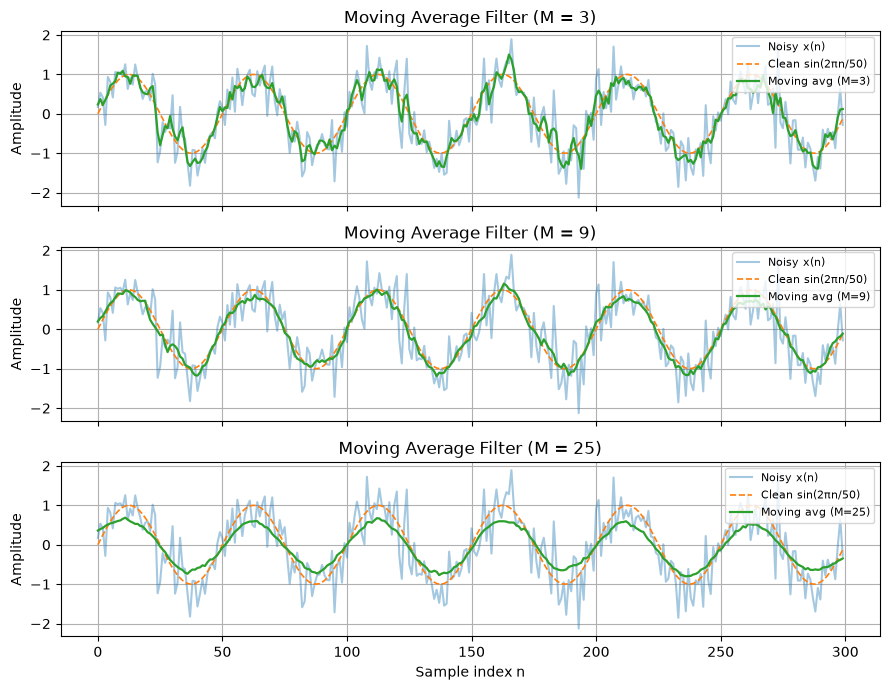

In [2]:
# Task 3.2: Smoothing a noisy signal by convolution
rng_smooth = np.random.default_rng(1)
n_vec = np.arange(0, 300)
w_noise = rng_smooth.standard_normal(len(n_vec))
x_noisy = np.sin(2 * np.pi * n_vec / 50.0) + 0.5 * w_noise
x_clean = np.sin(2 * np.pi * n_vec / 50.0)

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)

for ax, M in zip(axes, [3, 9, 25]):
    h_ma = np.ones(M) / M
    y_smooth = np.convolve(x_noisy, h_ma, mode="same")
    
    ax.plot(n_vec, x_noisy, alpha=0.4, label="Noisy x(n)")
    ax.plot(n_vec, x_clean, "--", linewidth=1.2, label="Clean sin(2πn/50)")
    ax.plot(n_vec, y_smooth, linewidth=1.6, label=f"Moving avg (M={M})")
    ax.set_ylabel("Amplitude")
    ax.set_title(f"Moving Average Filter (M = {M})")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True)

axes[-1].set_xlabel("Sample index n")
plt.tight_layout()
plt.show()

Task 3.3 — Testing linearity and time-invariance numerically 

In [3]:
# Task 3.3: Testing linearity and time-invariance numerically
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0

systems = {
    "x^2": lambda x: np.asarray(x) ** 2,
    "n * x(n)": lambda x: np.arange(len(x)) * np.asarray(x),
    "moving average": lambda x: np.convolve(np.asarray(x), np.ones(3) / 3)[: len(x)],
}

for name, T in systems.items():
    linear = np.allclose(T(a * x1 + b * x2), a * T(x1) + b * T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]       # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]    # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={str(linear):5s} time-invariant={str(tinv):5s}")

x^2             linear=False time-invariant=True 
n * x(n)        linear=True  time-invariant=False
moving average  linear=True  time-invariant=True 


Task 3.4 — Finding a hidden delay with cross-correlation

sigma = 0.5 | est_delay =   37 samples | time =  37.0 ms | distance (@343 m/s) = 12.69 m
sigma = 1.0 | est_delay =   37 samples | time =  37.0 ms | distance (@343 m/s) = 12.69 m
sigma = 2.0 | est_delay =   37 samples | time =  37.0 ms | distance (@343 m/s) = 12.69 m
sigma = 4.0 | est_delay =   37 samples | time =  37.0 ms | distance (@343 m/s) = 12.69 m


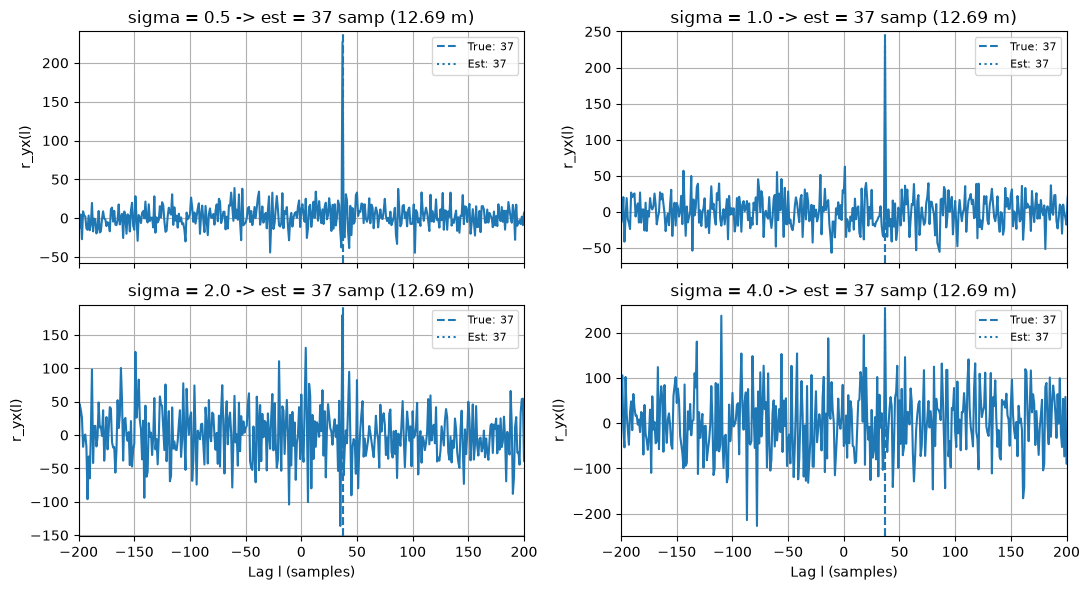

In [4]:
# Task 3.4: Finding a hidden delay with cross-correlation
rng_delay = np.random.default_rng(1)
fs_delay = 1000
x_tx = rng_delay.standard_normal(500)
true_delay = 37
sound_speed = 343.0  # m/s

noise_levels = [0.5, 1.0, 2.0, 4.0]
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)

for ax, sigma in zip(axes.ravel(), noise_levels):
    noise_vec = sigma * rng_delay.standard_normal(500)
    y_rx = np.concatenate([np.zeros(true_delay), 0.6 * x_tx])[:500] + noise_vec
    
    r_corr = signal.correlate(y_rx, x_tx, mode="full")
    lags = signal.correlation_lags(len(y_rx), len(x_tx), mode="full")
    
    est_lag = lags[np.argmax(r_corr)]
    delay_sec = est_lag / fs_delay
    distance_m = delay_sec * sound_speed
    
    ax.plot(lags, r_corr)
    ax.axvline(true_delay, linestyle="--", label=f"True: {true_delay}")
    ax.axvline(est_lag, linestyle=":", label=f"Est: {est_lag}")
    ax.set_xlim(-200, 200)
    ax.set_title(f"sigma = {sigma} -> est = {est_lag} samp ({distance_m:.2f} m)")
    ax.set_ylabel("r_yx(l)")
    ax.legend(fontsize=8)
    ax.grid(True)
    
    print(
        f"sigma = {sigma:3.1f} | est_delay = {est_lag:4d} samples "
        f"| time = {delay_sec*1e3:5.1f} ms | distance (@343 m/s) = {distance_m:5.2f} m"
    )

for ax in axes[1, :]:
    ax.set_xlabel("Lag l (samples)")

plt.tight_layout()
plt.show()

Task 3.5 — Difference equation 

Max diff (loop vs lfilter):    0.0
Max diff (loop vs closed-form): 0.0
All match:                     True


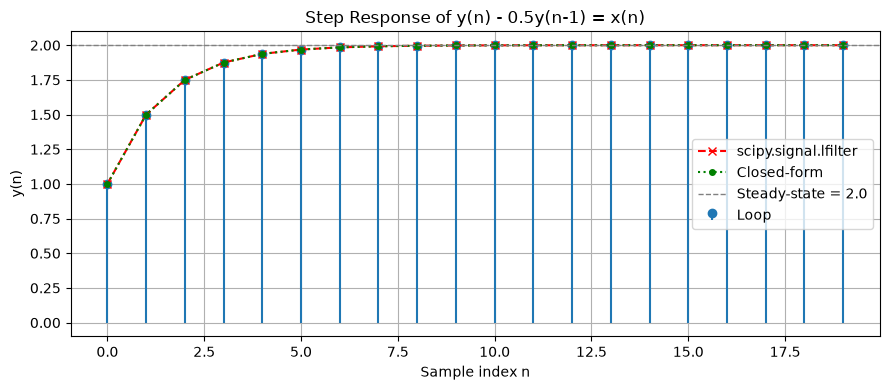

In [5]:
# Task 3.5: Difference equation
N_de = 20
n_de = np.arange(N_de)
x_step = np.ones(N_de)  # step input x(n) = u(n) for n = 0..19

# 1. Loop solution: y(n) = 0.5 * y(n-1) + x(n), with y(-1) = 0
y_loop = np.zeros(N_de)
for n in range(N_de):
    y_prev = y_loop[n - 1] if n > 0 else 0.0
    y_loop[n] = 0.5 * y_prev + x_step[n]

# 2. scipy.signal.lfilter solution
b_de = [1.0]
a_de = [1.0, -0.5]
y_lfilter = signal.lfilter(b_de, a_de, x_step)

# 3. Closed-form formula for step input x(n) = u(n): y(n) = 2 * (1 - 0.5**(n + 1))
y_closed = 2.0 * (1.0 - 0.5 ** (n_de + 1))

print("Max diff (loop vs lfilter):   ", np.max(np.abs(y_loop - y_lfilter)))
print("Max diff (loop vs closed-form):", np.max(np.abs(y_loop - y_closed)))
print("All match:                    ", np.allclose(y_loop, y_lfilter) and np.allclose(y_loop, y_closed))

plt.figure(figsize=(9, 4))
plt.stem(n_de, y_loop, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="Loop")
plt.plot(n_de, y_lfilter, "rx--", label="scipy.signal.lfilter")
plt.plot(n_de, y_closed, "g:o", markersize=4, label="Closed-form")
plt.axhline(2.0, linestyle="--", color="gray", linewidth=1, label="Steady-state = 2.0")
plt.title("Step Response of y(n) - 0.5y(n-1) = x(n)")
plt.xlabel("Sample index n")
plt.ylabel("y(n)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Pre-lab Questions (Week 3)

- **(a) Linear convolution of $x(n) = \{1, -1, 2\}$ and $h(n) = \{2, 1, 0, 1\}$:**  
  With $L = 3$ and $M = 4$, the output length is $N = 3 + 4 - 1 = 6$ samples ($n = 0, 1, 2, 3, 4, 5$):
  - $y(0) = 1(2) = 2$
  - $y(1) = 1(1) + (-1)(2) = -1$
  - $y(2) = 1(0) + (-1)(1) + 2(2) = 3$
  - $y(3) = 1(1) + (-1)(0) + 2(1) = 3$
  - $y(4) = (-1)(1) + 2(0) = -1$
  - $y(5) = 2(1) = 2$

  Thus, $y(n) = \{2,\ -1,\ 3,\ 3,\ -1,\ 2\}$.

- **(b) Closed-form step response of $y(n) - 0.5\,y(n-1) = x(n)$ for $x(n) = u(n)$ (with $y(-1) = 0$):**  
  Rewriting as $y(n) - 0.5\,y(n-1) = 1$ for $n \ge 0$:
  - Homogeneous solution: $y_h(n) = C\,(0.5)^n$
  - Particular (steady-state) solution: $y_p - 0.5\,y_p = 1 \implies 0.5\,y_p = 1 \implies y_p = 2$
  - Total response: $y(n) = 2 + C\,(0.5)^n$. Using $y(0) = 0.5(0) + 1 = 1$:
    $$2 + C(1) = 1 \implies C = -1$$
  - Therefore:
    $$y(n) = 2\left(1 - 0.5^{n+1}\right), \quad n \ge 0$$

## Analysis Questions (Week 3)

1. **Why `np.convolve` is much faster than a nested Python loop for length $2000$:**  
   A nested Python `for` loop executes millions of Python-level iterations with dynamic type checks, indexing overhead, and scalar arithmetic. In contrast, `np.convolve` runs compiled C/Cython code (and uses FFT-based convolution when lengths are large), avoiding Python interpreter overhead and operating on contiguous memory buffers.

2. **Trade-off between noise reduction and signal distortion as moving-average length $M$ increases:**  
   Increasing $M$ averages more neighboring samples, which reduces random zero-mean noise variance proportionally to $1/M$ and produces a smoother curve. However, a longer moving-average filter has a narrower low-pass cutoff and stronger attenuation at higher frequencies, causing greater signal attenuation, phase/edge smearing, and distortion of faster signal variations.

3. **Classification of the three systems in Task 3.3:**  
   - $T_1\{x(n)\} = x(n)^2$: **Non-linear** (squaring violates both homogeneity and additivity due to cross-terms), **Time-invariant** (shifting the input shifts the squared output identically).
   - $T_2\{x(n)\} = n\,x(n)$: **Linear** (scaling and adding inputs scales and adds outputs linearly), **Time-varying** (multiplying by a time-dependent index $n$ means a delayed input is multiplied by $n$ rather than $n - n_0$).
   - $T_3\{x(n)\}$ (3-point moving average): **Linear and Time-invariant (LTI)** (linear combination of shifted input samples with constant coefficients, aside from boundary truncation at the array edges).

4. **How cross-correlation estimates delay, and why it can fail at high noise ($\sigma$):**  
   Cross-correlation $r_{yx}(l) = \sum_n y(n)\,x(n - l)$ measures similarity between $y(n)$ and shifted versions of $x(n)$ across lags $l$; the lag maximizing $r_{yx}(l)$ estimates the delay $\hat{d}$, which maps to $\Delta t = \hat{d}/f_s$ and distance $d = c\,\Delta t$. When noise variance $\sigma^2$ grows large relative to signal energy, random correlation peaks caused by noise can exceed the true delay peak, leading to an incorrect lag estimate (`argmax`).

5. **Comparison of loop, `scipy.signal.lfilter`, and closed-form solutions for the difference equation:**  
   All three methods produce identical step response values for $y(n) - 0.5\,y(n-1) = u(n)$ (within floating-point precision), rising smoothly from $y(0) = 1$ toward the steady-state value of $2$ as $0.5^{n+1} \to 0$. The `for` loop is intuitive for learning recurrence step-by-step, `lfilter` is fast and general for arbitrary rational IIR/FIR filters in practice, and the closed-form expression gives direct analytical insight into transient decay rate and steady-state behavior without iterating sample-by-sample.